In [1]:
# QUERY - WHAT IS PHOTOSYNTHESIS?


# DOCUMENTS --
# "THE GRAND CANYON IS A FAMOUS NATURAL SITE ,"
# "PHOTOSYNTHESIS IS HOW PLANTS CONVERT LIGHT INTO ENERGY"
# "MANY TOURISTS VISIT EVERY YEAR"

# if we query search on this doc , we will be returned the whole paragraph
# even though the whole paragraph does not talk about photosynthesis , we will get the whole paragraph as the ans which will waste the LLM's context window

# for this we use contextual compression retriever

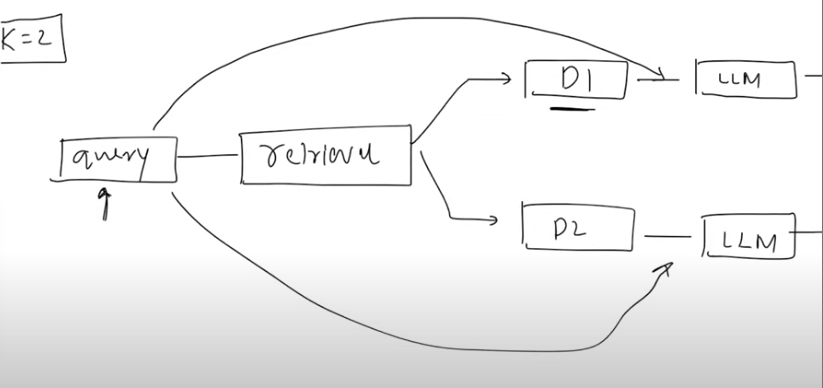

In [2]:
# we give the query to a normal retriever , which gives us 2 docs or k docs from the vector store , these docs are sent to the LLM + also the original query is also sent to the LLM , and then we write a prompt that based on the query , trim the documents given , therefore extra info will be trimmed and we get only relevant info.

In [5]:
from langchain.retrievers.contextual_compression import ContextualCompressionRetriever
from langchain.retrievers.document_compressors import LLMChainExtractor

In [ ]:
base_retriever = vectorstore.as_retriever(search_kwargs = { "k" : 5})

In [ ]:
llm = ChatOpenAI(model = 'gpt-3.5-turbo')
compressor = LLMChainExtractor.from_llm(llm)

In [ ]:
compression_retriever = ContextualCompressionRetriever(
    base_retriever = base_retriever,
    base_compressor=compressor
)

In [ ]:
results = compression_retriever.invoke(query)